# 05 · Ranked Shortlists, Explanations & Business Impact
Turning scores into something a recruiter can act on:
ranked shortlists per job, a reason for each candidate, skill-gap insights and the expected time savings.

In [1]:
# --- Setup -----------------------------------------------------------
# Add the project root folder to the Python path so "src" can be imported
import sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

# Standard libraries for data handling and charts
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")          # hide library warnings so the output stays readable
pd.set_option("display.max_columns", 60)   # show all columns when printing a dataframe
pd.set_option("display.max_colwidth", 80)  # do not cut long text too early

# Project settings: file paths, colours and the chart style
from src.config import *
from src.plot_style import set_style, save
set_style()

In [2]:
from src.matching import RULE_WEIGHTS

# scored candidate-job pairs from notebook 04
scored = pd.read_csv(SCORED_FILE)
for c in ["mandatory_matched", "mandatory_missing", "optional_matched"]:
    scored[c] = scored[c].fillna("").apply(lambda s: [x for x in str(s).split("|") if x])
cands = pd.read_csv(CANDIDATE_FEATURES_FILE)
jds = pd.read_csv(JD_FILE).set_index("jd_id")

# add candidate details that recruiters want to see next to the score
scored = scored.merge(cands[["candidate_id", "candidate_name", "primary_role", "primary_domain",
                             "highest_education", "education_field", "technical_skills_raw"]], on="candidate_id")
# rank inside each job (1 = best)
scored["rank"] = scored.groupby("jd_id")["hybrid_score"].rank(ascending=False, method="first").astype(int)
scored.shape

(50000, 61)

## 1. Recommendation summary per job

In [3]:
# How many candidates fall into each recommendation band for every job
summary = (pd.crosstab(scored["jd_id"], scored["recommendation"])[["Shortlist", "Review", "Reject"]]
             .assign(job_title=jds["job_title"]))
summary

recommendation,Shortlist,Review,Reject,job_title
jd_id,,,,
JD01,698,806,3496,Senior Cloud Backend Engineer
JD02,744,670,3586,DevOps Engineer
JD03,478,1678,2844,Junior Java Developer
JD04,534,97,4369,Data Scientist - NLP
JD05,251,737,4012,Business Data Analyst
JD06,219,255,4526,HR Business Partner
JD07,323,178,4499,Talent Acquisition Specialist
JD08,396,1,4603,Corporate Compliance Counsel
JD09,189,0,4811,Mechanical Design Engineer


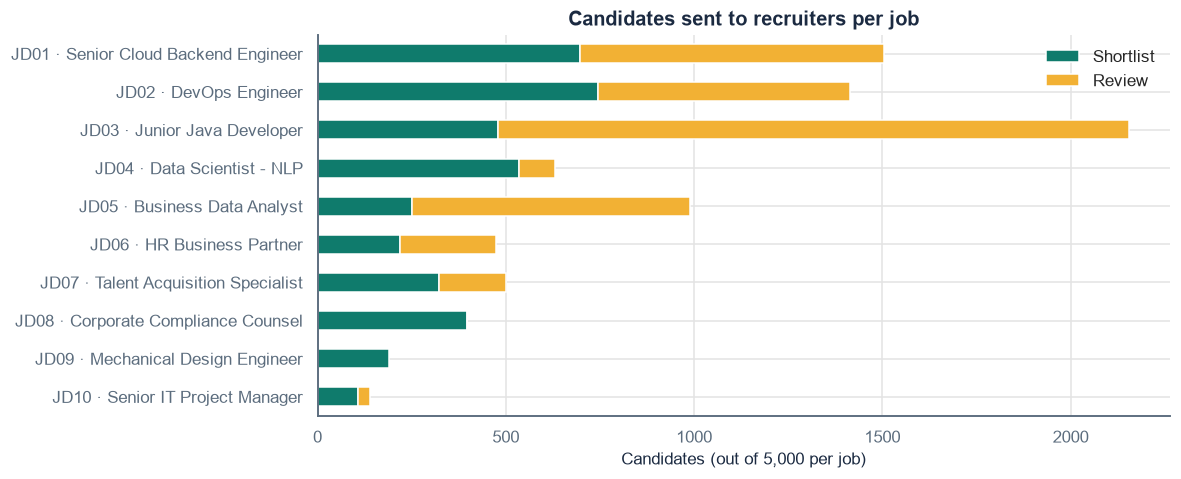

In [4]:
# Stacked bars: candidates sent to recruiters (Shortlist + Review) per job
fig, ax = plt.subplots(figsize=(10, 4.5))
plot = summary[["Shortlist", "Review"]].copy()
plot.index = [f"{i} · {jds.loc[i, 'job_title']}" for i in plot.index]
plot.plot.barh(stacked=True, ax=ax, color=[COLORS["teal"], COLORS["mustard"]])
ax.invert_yaxis()
ax.set_xlabel("Candidates (out of 5,000 per job)")
ax.set_title("Candidates sent to recruiters per job")
ax.legend(frameon=False)
save(fig, "05_recommendations_per_job")
plt.show()

## 2. Ranked shortlists with explanations

In [5]:
# Top 50 per job saved for recruiters; show the top 5 for two jobs here
cols = ["jd_id", "rank", "candidate_id", "candidate_name", "primary_role", "years_experience",
        "hybrid_score", "rule_score", "p_high", "lsa_sim", "recommendation", "explanation"]
shortlists = scored[scored["rank"] <= 50].sort_values(["jd_id", "rank"])[cols]
shortlists.round(3).to_csv(SHORTLIST_FILE, index=False)

for jd_id in ["JD01", "JD06"]:
    print(f"\n=== {jd_id}: {jds.loc[jd_id, 'job_title']} ===")
    display(shortlists[shortlists["jd_id"] == jd_id].head(5).drop(columns="jd_id").round(3))


=== JD01: Senior Cloud Backend Engineer ===


,rank,candidate_id,candidate_name,primary_role,years_experience,hybrid_score,rule_score,p_high,lsa_sim,recommendation,explanation
3468,1,CND_103469,Candidate_3469,DevOps Engineer,10,0.949,0.927,1.0,0.387,Shortlist,"3/3 must-have skills; bonus skills: Kubernetes, Linux; 10 yrs fits 6-15 yr r..."
1337,2,CND_101338,Candidate_1338,Senior Software Engineer,14,0.946,0.923,1.0,0.529,Shortlist,3/3 must-have skills; bonus skills: Git; 14 yrs fits 6-15 yr range; same dom...
2271,3,CND_102272,Candidate_2272,Senior Software Engineer,15,0.945,0.921,1.0,0.525,Shortlist,3/3 must-have skills; bonus skills: Git; 15 yrs fits 6-15 yr range; same dom...
1994,4,CND_101995,Candidate_1995,Software Engineer,9,0.943,0.919,1.0,0.426,Shortlist,"3/3 must-have skills; bonus skills: Kubernetes, Linux; 9 yrs fits 6-15 yr ra..."
4292,5,CND_104293,Candidate_4293,Senior Software Engineer,13,0.942,0.917,1.0,0.616,Shortlist,3/3 must-have skills; bonus skills: Kubernetes; 13 yrs fits 6-15 yr range; s...



=== JD06: HR Business Partner ===


,rank,candidate_id,candidate_name,primary_role,years_experience,hybrid_score,rule_score,p_high,lsa_sim,recommendation,explanation
25921,1,CND_100922,Candidate_922,HR Business Partner,10,0.968,0.954,1.0,0.749,Shortlist,"2/2 must-have skills; bonus skills: HRMS, Recruitment; 10 yrs fits 5-12 yr r..."
25261,2,CND_100262,Candidate_262,HR Business Partner,10,0.967,0.952,1.0,0.730,Shortlist,"2/2 must-have skills; bonus skills: Payroll, Recruitment; 10 yrs fits 5-12 y..."
25156,3,CND_100157,Candidate_157,Talent Acquisition Specialist,10,0.966,0.952,1.0,0.431,Shortlist,"2/2 must-have skills; bonus skills: HRMS, Payroll; 10 yrs fits 5-12 yr range..."
29220,4,CND_104221,Candidate_4221,HR Manager,12,0.965,0.951,1.0,0.532,Shortlist,"2/2 must-have skills; bonus skills: HRMS, Payroll; 12 yrs fits 5-12 yr range..."
29721,5,CND_104722,Candidate_4722,HR Manager,11,0.965,0.950,1.0,0.557,Shortlist,"2/2 must-have skills; bonus skills: HRMS, Payroll; 11 yrs fits 5-12 yr range..."


## 3. Why is one candidate ranked above another?
The rule score is a sum of weighted parts, so it can be broken down exactly. Below: the #1 candidate,
a borderline "Review" candidate and a "Reject" candidate for the same job.

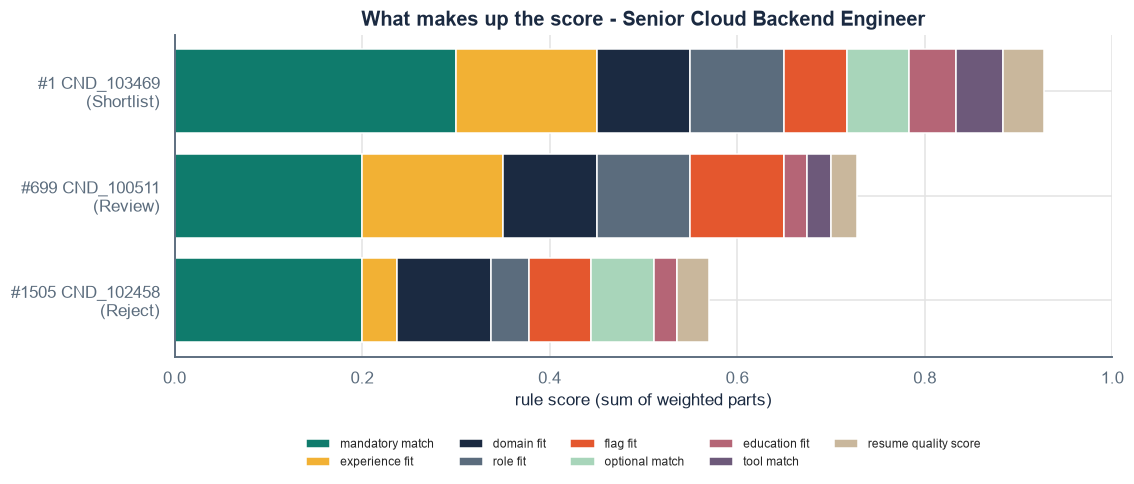

#1 CND_103469 (DevOps Engineer, Shortlist): 3/3 must-have skills; bonus skills: Kubernetes, Linux; 10 yrs fits 6-15 yr range; same domain
#699 CND_100511 (DevOps Engineer, Review): 2/3 must-have skills; missing: Docker; 10 yrs fits 6-15 yr range; same domain; has all required experience areas
#1505 CND_102458 (Junior Software Engineer, Reject): 2/3 must-have skills; missing: Docker; bonus skills: Kubernetes, Git; 3 yrs is below the 6 yr minimum; same domain


In [6]:
jd_id = "JD01"
g = scored[scored["jd_id"] == jd_id].sort_values("rank")
examples = pd.concat([
    g.head(1),                                                     # top ranked
    g[g["recommendation"] == "Review"].head(1),                    # best borderline
    g[(g["recommendation"] == "Reject") & (g["domain_fit"] > 0)].head(1),  # in-domain but rejected
])

# weighted contribution of each part of the rule score
contrib = pd.DataFrame({k: examples[k] * w for k, w in RULE_WEIGHTS.items()})
contrib.index = [f"#{r} {c}\n({rec})" for r, c, rec in zip(examples["rank"], examples["candidate_id"], examples["recommendation"])]

fig, ax = plt.subplots(figsize=(11, 3.8))
left = np.zeros(len(contrib))
colors = [COLORS["teal"], COLORS["mustard"], COLORS["ink"], COLORS["slate"], COLORS["coral"],
          COLORS["mint"], "#B56576", "#6D597A", "#C9B79C"]
for col, colr in zip(contrib.columns, colors):
    ax.barh(contrib.index, contrib[col], left=left, color=colr, label=col.replace("_", " "))
    left += contrib[col].values
ax.invert_yaxis()
ax.set_xlim(0, 1)
ax.set_xlabel("rule score (sum of weighted parts)")
ax.set_title(f"What makes up the score - {jds.loc[jd_id, 'job_title']}")
ax.legend(ncol=5, fontsize=8, frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.22))
save(fig, "05_score_breakdown")
plt.show()

for _, r in examples.iterrows():
    print(f"#{r['rank']} {r['candidate_id']} ({r['primary_role']}, {r['recommendation']}): {r['explanation']}")

## 4. Skill-gap insights for recruiters and hiring managers

In [7]:
# Among candidates in the 'Review' band, which must-have skill is missing most often?
review = scored[scored["recommendation"] == "Review"].explode("mandatory_missing").dropna(subset=["mandatory_missing"])
gaps = (review.groupby(["jd_id", "mandatory_missing"]).size().rename("candidates")
              .reset_index().sort_values(["jd_id", "candidates"], ascending=[True, False])
              .groupby("jd_id").head(1).set_index("jd_id"))
gaps["review_pool"] = scored[scored["recommendation"] == "Review"].groupby("jd_id").size()
gaps["share_of_review_pool"] = (gaps["candidates"] / gaps["review_pool"]).round(2)
gaps.assign(job_title=jds["job_title"]).to_csv(OUTPUTS / "skill_gaps_review_pool.csv")
gaps.assign(job_title=jds["job_title"])

,mandatory_missing,candidates,review_pool,share_of_review_pool,job_title
jd_id,,,,,
JD01,Docker,258,806,0.32,Senior Cloud Backend Engineer
JD02,Docker,225,670,0.34,DevOps Engineer
JD03,Java,802,1678,0.48,Junior Java Developer
JD04,Machine Learning,32,97,0.33,Data Scientist - NLP
JD05,Power BI,411,737,0.56,Business Data Analyst
JD06,Employee Engagement,88,255,0.35,HR Business Partner
JD07,HRMS,83,178,0.47,Talent Acquisition Specialist


**Insight:** for most jobs the "Review" pool is held back by **one** missing must-have skill. If a hiring manager can
accept that skill as *trainable* (moving it from mandatory to optional), the shortlist grows a lot without lowering quality
on everything else. This gives recruiters a concrete, data-backed question to ask the hiring manager.

## 5. How many good candidates would a keyword filter miss?
A basic ATS keyword filter looks for the must-have skills **spelt exactly** in the raw text. To make it a fair
comparison, the keyword filter uses the **same threshold** as the "High" rule (at least 2/3 of must-have skills found) —
the *only* difference is that it does not understand misspellings.

In [8]:
def keyword_pass(raw_skills, tools_raw, mandatory):
    # exact, case-sensitive keyword check on the raw text (what a basic ATS does),
    # using the same ">= 2/3 of must-have skills" threshold as the High-fit rule
    tokens = [t.strip() for t in f"{raw_skills}, {tools_raw}".split(",")]
    found = sum(m in tokens for m in mandatory)
    return found / len(mandatory) >= 0.66

raw = pd.read_csv(RAW_DATA)[["candidate_id", "tools_platforms_raw"]]
kw = scored.merge(raw, on="candidate_id")
kw["keyword_filter_pass"] = [keyword_pass(s, t, jds.loc[j, "mandatory_skills"].split("|"))
                             for s, t, j in zip(kw["technical_skills_raw"], kw["tools_platforms_raw"], kw["jd_id"])]

missed = (kw[kw["fit_label"] == "High"].groupby("jd_id")
            .agg(high_fit=("candidate_id", "size"), missed_by_keyword=("keyword_filter_pass", lambda s: (~s).sum())))
missed["missed_pct"] = (missed["missed_by_keyword"] / missed["high_fit"] * 100).round(1)
print(f"Overall: a keyword filter would drop {missed['missed_by_keyword'].sum()} of "
      f"{missed['high_fit'].sum()} High-fit candidate-job matches ({missed['missed_by_keyword'].sum()/missed['high_fit'].sum():.1%}).")
missed.assign(job_title=jds["job_title"]).to_csv(OUTPUTS / "keyword_filter_miss.csv")
missed.assign(job_title=jds["job_title"])

Overall: a keyword filter would drop 370 of 3772 High-fit candidate-job matches (9.8%).


,high_fit,missed_by_keyword,missed_pct,job_title
jd_id,,,,
JD01,687,37,5.4,Senior Cloud Backend Engineer
JD02,738,109,14.8,DevOps Engineer
JD03,446,34,7.6,Junior Java Developer
JD04,530,43,8.1,Data Scientist - NLP
JD05,243,16,6.6,Business Data Analyst
JD06,211,36,17.1,HR Business Partner
JD07,277,33,11.9,Talent Acquisition Specialist
JD08,346,42,12.1,Corporate Compliance Counsel
JD09,189,17,9.0,Mechanical Design Engineer


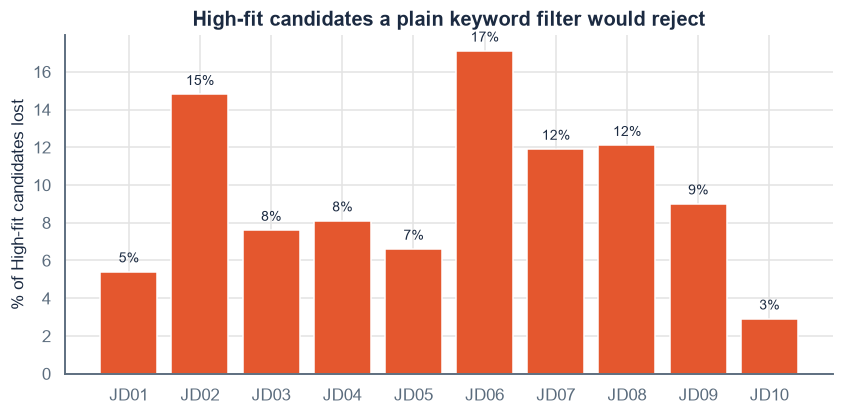

In [9]:
# Chart: share of High-fit candidates each job would lose with an exact keyword filter
fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(missed.index, missed["missed_pct"], color=COLORS["coral"])
for i, v in enumerate(missed["missed_pct"]):
    ax.text(i, v + 0.5, f"{v:.0f}%", ha="center", fontsize=9, color=COLORS["ink"])
ax.set_ylabel("% of High-fit candidates lost")
ax.set_title("High-fit candidates a plain keyword filter would reject")
save(fig, "05_keyword_filter_miss")
plt.show()

## 6. Recruiter workload and time saved
**Assumptions (stated clearly so they can be changed):**
- A recruiter spends **5 minutes** reading a resume manually.
- *Today:* recruiters pre-filter by domain and then read **every** resume in that domain (plus related domains).
- *With the engine:* recruiters read only **Shortlist + Review** candidates; "Reject" is auto-archived with its reason.

In [10]:
MINUTES_PER_RESUME = 5

rows = []
for jd_id, g in scored.groupby("jd_id"):
    manual = (g["domain_fit"] > 0).sum()                                   # today's workload
    engine = g["recommendation"].isin(["Shortlist", "Review"]).sum()       # with the engine
    high_kept = (g.loc[g["fit_label"] == "High", "recommendation"] != "Reject").mean()
    rows.append({"jd_id": jd_id, "job_title": jds.loc[jd_id, "job_title"],
                 "resumes_read_today": manual, "resumes_read_with_engine": engine,
                 "high_fit_retained": round(high_kept, 3)})
workload = pd.DataFrame(rows).set_index("jd_id")
workload["reduction_pct"] = ((1 - workload["resumes_read_with_engine"] / workload["resumes_read_today"]) * 100).round(1)
workload["hours_saved"] = ((workload["resumes_read_today"] - workload["resumes_read_with_engine"]) * MINUTES_PER_RESUME / 60).round(1)
workload.to_csv(OUTPUTS / "workload_impact.csv")

total_today, total_engine = workload["resumes_read_today"].sum(), workload["resumes_read_with_engine"].sum()
print(f"Across 10 jobs: {total_today:,} -> {total_engine:,} resumes to read "
      f"({1 - total_engine/total_today:.0%} less), about {workload['hours_saved'].sum():,.0f} recruiter hours saved.")
workload

Across 10 jobs: 21,782 -> 8,393 resumes to read (61% less), about 1,116 recruiter hours saved.


,job_title,resumes_read_today,resumes_read_with_engine,high_fit_retained,reduction_pct,hours_saved
jd_id,,,,,,
JD01,Senior Cloud Backend Engineer,3774,1504,1.0,60.1,189.2
JD02,DevOps Engineer,2772,1414,1.0,49.0,113.2
JD03,Junior Java Developer,2772,2156,1.0,22.2,51.3
JD04,Data Scientist - NLP,3774,631,1.0,83.3,261.9
JD05,Business Data Analyst,3913,988,1.0,74.8,243.8
JD06,HR Business Partner,640,474,1.0,25.9,13.8
JD07,Talent Acquisition Specialist,501,501,1.0,0.0,0.0
JD08,Corporate Compliance Counsel,536,397,1.0,25.9,11.6
JD09,Mechanical Design Engineer,189,189,1.0,0.0,0.0


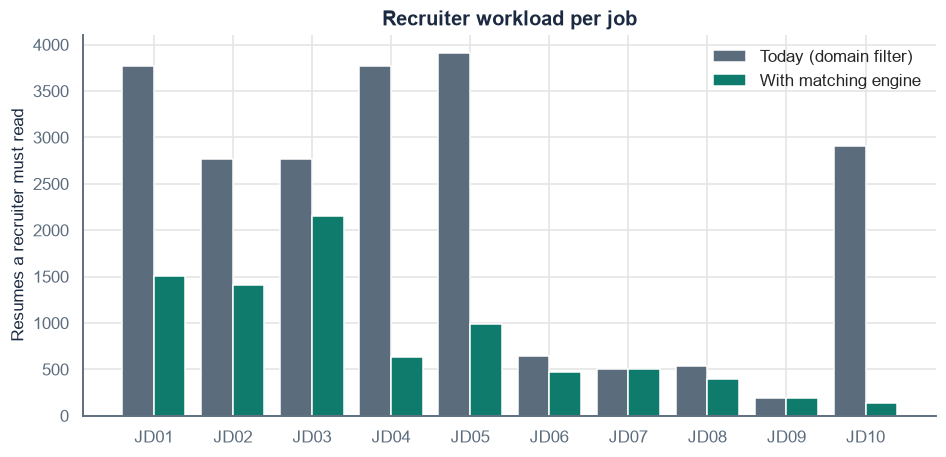

In [11]:
# Side-by-side bars: resumes to read today vs with the engine
fig, ax = plt.subplots(figsize=(10, 4.5))
x = np.arange(len(workload))
ax.bar(x - 0.2, workload["resumes_read_today"], width=0.4, color=COLORS["slate"], label="Today (domain filter)")
ax.bar(x + 0.2, workload["resumes_read_with_engine"], width=0.4, color=COLORS["teal"], label="With matching engine")
ax.set_xticks(x, workload.index)
ax.set_ylabel("Resumes a recruiter must read")
ax.set_title("Recruiter workload per job")
ax.legend(frameon=False)
save(fig, "05_workload")
plt.show()

## 7. Recommendations for recruiters
1. **Use the hybrid score to order the queue** — read *Shortlist* first, then *Review*; auto-archive *Reject* with its stored reason (auditability).
2. **Turn on fuzzy skill matching in the ATS** — exact keyword filters drop a measurable share of High-fit candidates because of typos.
3. **Challenge "mandatory" skills with hiring managers** — the skill-gap table shows the one skill holding back most Review candidates.
4. **Keep institution tier out of screening** — it carries no fit signal and the fairness check shows equal shortlist rates across tiers.
5. **Close the loop** — log recruiter decisions on each shortlist, then re-train the model on real outcomes every quarter.
6. **Write JDs in the structured format** (must-have vs nice-to-have, experience range, required experience areas) — the engine is only as good as the JD.